# Hierarchical Clustering 
## 1: Tiếp nhận và kiểm tra dữ liệu bàn giao

**Mục tiêu:** tạo `X` (đặc trưng đầu vào), `y_reference` (nhãn chỉ dùng để đánh giá)
và `sample_ids` (thông tin nhận dạng mẫu), đúng với dữ liệu K-Means của Thành.

Notebook này mới có bước 1, chưa huấn luyện Hierarchical. Các ô mã chỉ đọc dữ liệu,
kiểm tra và hiển thị; không ghi đè dữ liệu hoặc kết quả của nhóm, không thao tác Git.

**Cách dùng:** đặt file vào thư mục `notebooks` của bản repository trên máy;
mở cả thư mục `human-activity-clustering` trong VS Code; chọn kernel Python và chạy
từng ô từ trên xuống. Cần có `numpy`, `pandas` và `ipykernel` trong kernel đã chọn.

Được chuẩn bị theo nhánh main tại commit `7a6608c` đã kiểm tra ngày 19/11/2026.
File được phát hành với các ô chưa chạy để bạn tự thực hiện và quan sát kết quả.


### 1.1. Nạp thư viện
`pandas` đọc bảng CSV; `numpy` xử lý ma trận số. `Path` giúp viết đường dẫn
không phụ thuộc dấu gạch chéo của Windows. `json` đọc cấu hình bàn giao.

Nếu ô này báo thiếu thư viện, kiểm tra kernel đang chọn trước khi cài thêm.


In [2]:
%pip install pandas

   ---------------------------------------- 0.0/10.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.8 MB ? eta -:--:--
    --------------------------------------- 0.3/10.8 MB ? eta -:--:--
    --------------------------------------- 0.3/10.8 MB ? eta -:--:--
    --------------------------------------- 0.3/10.8 MB ? eta -:--:--
   - -------------------------------------- 0.5/10.8 MB 409.6 kB/s eta 0:00:25
   - -------------------------------------- 0.5/10.8 MB 409.6 kB/s eta 0:00:25
   -- ------------------------------------- 0.8/10.8 MB 459.9 kB/s eta 0:00:22
   -- ------------------------------------- 0.8/10.8 MB 459.9 k


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
from IPython.display import display

print("Đã nạp thư viện.")


Đã nạp thư viện.


### 1.2. Xác định thư mục dự án
Thư mục gốc phải chứa cả `data`, `results` và `notebooks`.
Mã tìm từ thư mục đang chạy lên các thư mục cha, nên dùng được khi notebook
chạy từ thư mục gốc hoặc thư mục `notebooks`.

Nếu không tìm thấy, sửa `PROJECT_FOLDER` thành đường dẫn thư mục repository của bạn.
Ví dụ: `PROJECT_FOLDER = r"D:\HocTap\human-activity-clustering"`.


In [5]:
PROJECT_FOLDER = ""  # Để trống nếu đã mở đúng thư mục dự án trong VS Code.

if PROJECT_FOLDER:
    ROOT = Path(PROJECT_FOLDER).expanduser().resolve()
else:
    current = Path.cwd().resolve()
    ROOT = next(
        (p for p in [current, *current.parents]
         if (p / "results/preprocessing_config.json").is_file()
         and (p / "data/processed/sample_indices.csv").is_file()),
        None,
    )

if ROOT is None or not (ROOT / "results/preprocessing_config.json").is_file():
    raise FileNotFoundError(
        "Chưa tìm thấy thư mục dự án. Hãy đặt PROJECT_FOLDER thành đường dẫn repository."
    )

config_path = ROOT / "results/preprocessing_config.json"
config = json.loads(config_path.read_text(encoding="utf-8-sig"))
data_path = ROOT / config["sample_files"]["sampled_pca_data"]
indices_path = ROOT / config["sample_files"]["indices_file"]

print("Thư mục dự án:", ROOT)
print("Dữ liệu đầu vào:", data_path.name)
print("Số mẫu theo cấu hình:", config["sample_size"])
print("Số thành phần PCA:", config["pca_components"])
print("Phương sai giữ lại (%):", config["pca_cumulative_variance"])


Thư mục dự án: C:\Users\Admin\Downloads\KhaiPhaDuLieu\human-activity-clustering
Dữ liệu đầu vào: sampled_data_scaled_pca.csv
Số mẫu theo cấu hình: 3000
Số thành phần PCA: 104
Phương sai giữ lại (%): 95.05


### 1.3. Đọc dữ liệu đã chuẩn bị
`data` là bảng mẫu sau chuẩn hóa và PCA, có kèm thông tin tham chiếu.
`indices` lưu vị trí mẫu trong tập 3.000 dòng và trong dữ liệu gốc.

Kết quả dự kiến: `data` có **3.000 dòng × 108 cột**, `indices` có **3.000 dòng × 5 cột**.
Ở đây chỉ đọc các file đã có, không lấy mẫu hay tính PCA lại.


In [6]:
data = pd.read_csv(data_path)
indices = pd.read_csv(indices_path)

print("Kích thước bảng dữ liệu:", data.shape)
print("Kích thước bảng chỉ số:", indices.shape)
display(data[["PC1", "PC2", "PC3", "ActivityName", "Original_Index"]].head())
display(indices.head())


Kích thước bảng dữ liệu: (3000, 108)
Kích thước bảng chỉ số: (3000, 5)


,PC1,PC2,PC3,ActivityName,Original_Index
0,-15.644768,4.620174,-2.128847,STANDING,5
1,-15.181595,3.005875,-1.492704,STANDING,6
2,-15.507233,1.928011,-0.096154,STANDING,7
3,-15.776544,3.088752,-0.251686,STANDING,8
4,-16.428789,7.361323,-1.401795,STANDING,11


,Sample_Index,Original_Index,Subject,Activity,ActivityName
0,0,5,1,5,STANDING
1,1,6,1,5,STANDING
2,2,7,1,5,STANDING
3,3,8,1,5,STANDING
4,4,11,1,5,STANDING


### 1.4. Tách đặc trưng và nhãn tham chiếu
- `X`: chỉ các cột `PC1` đến `PC104`, sẽ đưa vào Hierarchical ở bước sau.
- `y_reference`: hoạt động thực tế, giữ riêng để tính ARI/NMI sau phân cụm.
- `sample_ids`: xác định mỗi kết quả thuộc mẫu nào.

Chọn rõ tên cột PCA để không vô tình đưa `Activity`, `ActivityName`, `Subject`
hoặc `Original_Index` vào mô hình. Không dùng `data.values` cho toàn bộ bảng.


In [7]:
feature_columns = [f"PC{i}" for i in range(1, config["pca_components"] + 1)]
metadata_columns = ["Activity", "ActivityName", "Subject", "Original_Index"]

assert set(feature_columns + metadata_columns).issubset(data.columns), "Thiếu cột dữ liệu."
X = data.loc[:, feature_columns].to_numpy(dtype=np.float64)
y_reference = data["Activity"].to_numpy(copy=True)
sample_ids = indices[["Sample_Index", "Original_Index"]].copy()

print("X — đầu vào mô hình:", X.shape)
print("y_reference — nhãn giữ riêng:", y_reference.shape)
print("Các cột không đưa vào X:", metadata_columns)


X — đầu vào mô hình: (3000, 104)
y_reference — nhãn giữ riêng: (3000,)
Các cột không đưa vào X: ['Activity', 'ActivityName', 'Subject', 'Original_Index']


### 1.5. Kiểm tra chất lượng và thứ tự mẫu
`assert` có nghĩa là: nếu điều kiện không đúng thì dừng và thông báo để kiểm tra.
Không xóa các kiểm tra để chạy tiếp khi có lỗi.

Chúng ta kiểm tra: đủ số mẫu, đủ đặc trưng, không có NaN/vô cực, chỉ số mẫu
không bị lặp, và thông tin từng dòng khớp giữa hai file. Sau đó đối chiếu nhãn
với dữ liệu gốc theo `Original_Index`. Việc này chỉ kiểm tra bàn giao, không chọn K.


In [8]:
assert config["sample_size"] == 3000, "Cấu hình số mẫu khác bản đã thống nhất."
assert config["pca_components"] == 104, "Cấu hình PCA khác bản đã thống nhất."
assert X.shape == (3000, 104), "Sai kích thước X."
assert len(indices) == len(data), "Hai file khác số dòng."
assert np.isfinite(X).all(), "X có NaN hoặc vô cực."
assert not data[metadata_columns].isna().any().any(), "Thiếu thông tin tham chiếu."
assert data["Original_Index"].is_unique, "Mẫu có chỉ số gốc bị lặp."
assert np.array_equal(indices["Sample_Index"].to_numpy(), np.arange(3000)), "Sai Sample_Index."

for column in metadata_columns:
    assert data[column].equals(indices[column]), f"Sai thứ tự hoặc thông tin ở cột {column}."

raw_dir = ROOT / "data/raw/UCI HAR Dataset"
original_y = np.concatenate([
    np.loadtxt(raw_dir / "train/y_train.txt", dtype=int),
    np.loadtxt(raw_dir / "test/y_test.txt", dtype=int),
])
original_indices = data["Original_Index"].to_numpy()
assert np.issubdtype(original_indices.dtype, np.integer), "Chỉ số gốc phải là số nguyên."
assert ((original_indices >= 0) & (original_indices < len(original_y))).all(), "Chỉ số gốc vượt phạm vi."
assert np.array_equal(original_y[original_indices], y_reference), "Nhãn lệch so với dữ liệu gốc."

print("ĐẠT: kích thước, giá trị số, chỉ số mẫu, thứ tự dòng và nhãn tham chiếu.")


ĐẠT: kích thước, giá trị số, chỉ số mẫu, thứ tự dòng và nhãn tham chiếu.


### 1.6. Xác nhận dùng đúng đầu vào của K-Means
Đọc kết quả trong `results/kmeans/`, không dùng kết quả sơ bộ trên 10.299 mẫu.

Ngoài kiểm tra thứ tự dòng, SHA-256 là dấu kiểm tra nội dung file mà Thành đã lưu.
Trên Windows, Git có thể đổi ký tự xuống dòng từ LF sang CRLF. Vì vậy, mã kiểm tra
cả nội dung nguyên trạng lẫn nội dung chỉ chuẩn hóa ký tự xuống dòng về LF;
không sửa file và không thay đổi các giá trị dữ liệu.


In [9]:
kmeans_dir = ROOT / "results/kmeans"
kmeans_config = json.loads((kmeans_dir / "experiment_config.json").read_text(encoding="utf-8-sig"))
kmeans_labels = pd.read_csv(kmeans_dir / "cluster_labels.csv")

assert kmeans_config["input_shape"] == list(X.shape), "K-Means dùng kích thước đầu vào khác."
assert kmeans_config["feature_columns"] == feature_columns, "Khác bộ hoặc thứ tự đặc trưng."
assert len(kmeans_labels) == len(data), "Kết quả K-Means khác số mẫu."
for column in ["Sample_Index", "Original_Index", "Activity", "ActivityName", "Subject"]:
    assert kmeans_labels[column].equals(indices[column]), f"K-Means lệch mẫu hoặc thông tin: {column}."

for relative_path, expected_hash in kmeans_config["inputs"].items():
    file_bytes = (ROOT / relative_path).read_bytes()
    hashes = {
        hashlib.sha256(file_bytes).hexdigest(),
        hashlib.sha256(file_bytes.replace(b"\r\n", b"\n")).hexdigest(),
    }
    assert expected_hash in hashes, f"File khác đầu vào K-Means đã lưu: {relative_path}"

print("ĐẠT: cùng dữ liệu, cùng 104 đặc trưng và cùng thứ tự mẫu với K-Means.")
print("K chính của K-Means:", kmeans_config["selected_k"])


ĐẠT: cùng dữ liệu, cùng 104 đặc trưng và cùng thứ tự mẫu với K-Means.
K chính của K-Means: 2


### 1.7. Kết luận 
Nếu chạy đến ô dưới không có lỗi, dữ liệu đã sẵn sàng cho bước chạy Ward.
Các biến đang nằm trong bộ nhớ của kernel; nếu khởi động lại kernel, chạy lại các ô.


In [11]:
print("HOÀN THÀNH")
print("Đặc trưng dùng phân cụm: X, kích thước", X.shape)
print("Nhãn dành cho đánh giá: y_reference, kích thước", y_reference.shape)
print("Chỉ số để ghép kết quả: sample_ids, kích thước", sample_ids.shape)
print("Chưa chạy Hierarchical và chưa thay đổi dữ liệu bàn giao.")

display(data["ActivityName"].value_counts().rename_axis("Hoạt động").to_frame("Số mẫu"))


HOÀN THÀNH
Đặc trưng dùng phân cụm: X, kích thước (3000, 104)
Nhãn dành cho đánh giá: y_reference, kích thước (3000,)
Chỉ số để ghép kết quả: sample_ids, kích thước (3000, 2)
Chưa chạy Hierarchical và chưa thay đổi dữ liệu bàn giao.


,Số mẫu
Hoạt động,
LAYING,566
STANDING,555
SITTING,518
WALKING,502
WALKING_UPSTAIRS,450
WALKING_DOWNSTAIRS,409


Chạy Agglomerative Hierarchical Clustering với Ward trên `X`,
khảo sát số cụm và vẽ Dendrogram. Chưa thực hiện bước đó trong bản notebook này.


##  2. Xây dựng cây phân cụm Hierarchical với Ward
###  Nạp thư viện

In [13]:
%pip install scipy matplotlib

   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/36.7 MB ? eta -:--:--
    --------------------------------------- 0.5/36.7 MB 1.3 MB/s eta 0:00:28
    --------------------------------------- 0.5/36.7 MB 1.3 MB/s eta 0:00:28
    --------------------------------------- 0.5/36.7 MB 1.3 MB/s eta 0:00:28
    --------------------------------------- 0.8/36.7 MB 671.3 kB/s eta 0:00:54
    --------------------------------------- 0.8/36.7 MB 671.3 kB/s eta 0:00:54
   - -------------------------------------- 1.0/36.7 MB 671.6 kB/s eta 0:00:54
   - -------------------------------------- 1.0/36.7 MB 671.6 kB/s eta 0:00:54
   - -------------------------------------- 1.0/36.7 MB 671.6 kB/s eta 0:00:54
   - -------------------------------------- 1.3/36.7 MB 573.6 kB/s eta 0:01:02
   - ----------


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

print("Đã nạp thư viện cho Hierarchical Clustering.")

Đã nạp thư viện cho Hierarchical Clustering.


### Xây dựng cây Ward
Sử dụng toàn bộ 3.000 mẫu và 104 thành phần PCA đã kiểm tra.
Không đưa nhãn hoạt động vào thuật toán.

In [15]:
assert X.shape == (3000, 104), "Cần chạy lại bước 1 để kiểm tra X."

# Xây dựng toàn bộ cây phân cụm bằng Ward.
Z = linkage(
    X,
    method="ward",
    metric="euclidean"
)

print("Đã xây dựng cây phân cụm Ward.")
print("Kích thước ma trận liên kết Z:", Z.shape)
print("Số lần gộp cụm:", len(Z))
print("Số mẫu trong cụm cuối cùng:", int(Z[-1, 3]))

Đã xây dựng cây phân cụm Ward.
Kích thước ma trận liên kết Z: (2999, 4)
Số lần gộp cụm: 2999
Số mẫu trong cụm cuối cùng: 3000


### Trực quan hóa cây phân cụm bằng Dendrogram
Hiển thị cây dạng rút gọn để dễ đọc.
Cây vẫn được tính từ đầy đủ 3.000 mẫu và 104 đặc trưng.
Biểu đồ Dendrogram

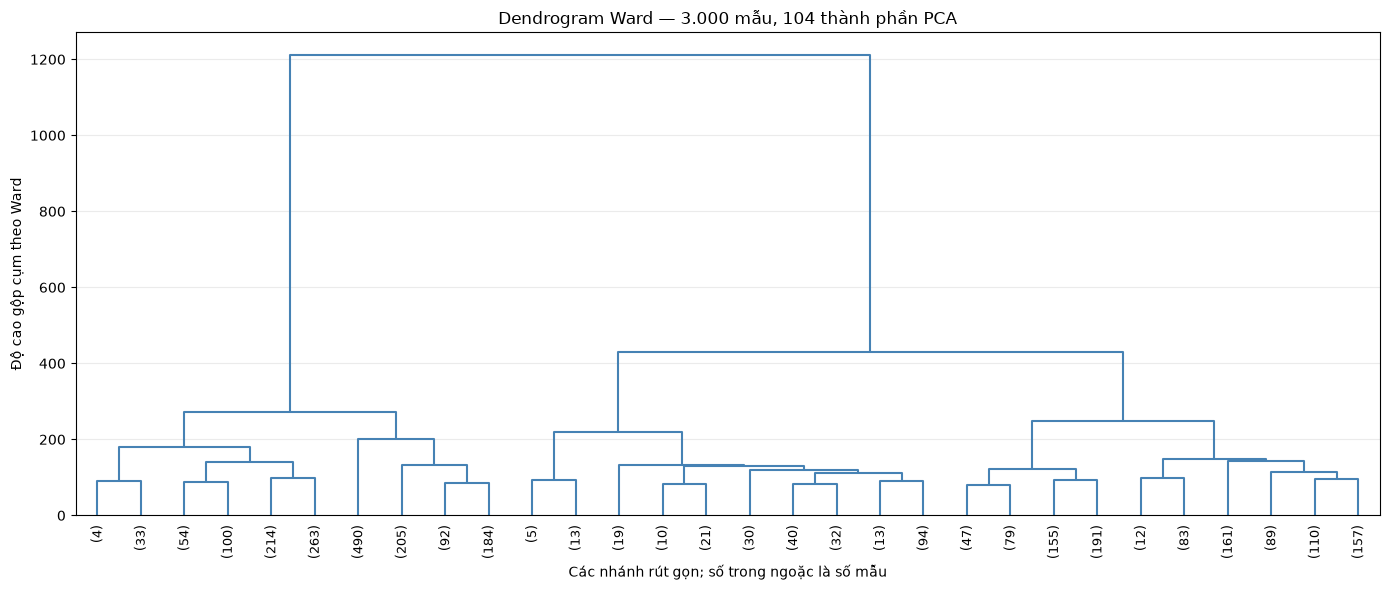

In [16]:
fig, ax = plt.subplots(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=90,
    leaf_font_size=9,
    color_threshold=0,
    above_threshold_color="steelblue",
    ax=ax
)

ax.set_title("Dendrogram Ward — 3.000 mẫu, 104 thành phần PCA")
ax.set_xlabel("Các nhánh rút gọn; số trong ngoặc là số mẫu")
ax.set_ylabel("Độ cao gộp cụm theo Ward")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

## 3: Khảo sát số cụm và đánh giá nội bộ

Cắt cây Ward với K từ 2 đến 10.
Đánh giá trên toàn bộ 3.000 mẫu trong không gian 104 thành phần PCA.

Chọn K theo Silhouette cao nhất; nếu bằng nhau, ưu tiên K nhỏ hơn.
Không sử dụng nhãn hoạt động để lựa chọn K.

In [17]:
%pip install scikit-learn threadpoolctl

   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ------------ --------------------------- 2.6/8.3 MB 21.6 MB/s eta 0:00:01
   ---------------------------------------- 8.3/8.3 MB 39.4 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from scipy.cluster.hierarchy import cut_tree
from sklearn.metrics import (
    pairwise_distances,
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)
from threadpoolctl import threadpool_limits

assert "X" in globals() and "Z" in globals(), (
    "Hãy chạy lại bước 1 và bước 2 để tạo X và Z."
)
assert X.shape == (3000, 104)
assert Z.shape == (2999, 4)

print("Đã sẵn sàng khảo sát K từ 2 đến 10.")

Đã sẵn sàng khảo sát K từ 2 đến 10.


In [19]:
k_values = list(range(2, 11))

# Mỗi cột chứa nhãn cụm của 3.000 mẫu ứng với một giá trị K.
label_matrix = cut_tree(Z, n_clusters=k_values)

labels_hierarchical_by_k = {}
evaluation_rows = []

# Dùng một luồng tính toán, tương tự cấu hình thực nghiệm K-Means.
with threadpool_limits(limits=1):

    # Tính khoảng cách Euclidean trên đủ 104 chiều, dùng lại cho mọi K.
    distances_hierarchical = pairwise_distances(X, metric="euclidean")
    np.fill_diagonal(distances_hierarchical, 0.0)

    for column_index, k in enumerate(k_values):
        labels = label_matrix[:, column_index].astype(int)

        assert len(np.unique(labels)) == k, f"K={k}: số cụm không đúng."
        labels_hierarchical_by_k[k] = labels.copy()

        cluster_sizes = np.bincount(labels)

        sil = silhouette_score(
            distances_hierarchical,
            labels,
            metric="precomputed"
        )
        db = davies_bouldin_score(X, labels)
        ch = calinski_harabasz_score(X, labels)

        evaluation_rows.append({
            "K": k,
            "Silhouette": sil,
            "Davies_Bouldin": db,
            "Calinski_Harabasz": ch,
            "Min_cluster_size": int(cluster_sizes.min()),
            "Max_cluster_size": int(cluster_sizes.max()),
        })

        print(
            f"K={k}: Silhouette={sil:.6f}, "
            f"DB={db:.6f}, CH={ch:.6f}",
            flush=True
        )

hierarchical_results = pd.DataFrame(evaluation_rows)

print("\nBẢNG ĐÁNH GIÁ HIERARCHICAL:")
display(hierarchical_results.round(6))

K=2: Silhouette=0.415037, DB=1.011878, CH=2562.366845
K=3: Silhouette=0.359396, DB=1.624952, CH=1614.609482
K=4: Silhouette=0.163656, DB=2.238757, CH=1181.438392
K=5: Silhouette=0.095319, DB=2.618447, CH=957.673150
K=6: Silhouette=0.098511, DB=2.445107, CH=815.023448
K=7: Silhouette=0.071267, DB=2.355499, CH=715.196129
K=8: Silhouette=0.077361, DB=2.270394, CH=639.197799
K=9: Silhouette=0.076194, DB=2.269641, CH=575.682892
K=10: Silhouette=0.065053, DB=2.393432, CH=525.408895

BẢNG ĐÁNH GIÁ HIERARCHICAL:


,K,Silhouette,Davies_Bouldin,Calinski_Harabasz,Min_cluster_size,Max_cluster_size
0,2,0.415037,1.011878,2562.366845,1361,1639
1,3,0.359396,1.624952,1614.609482,277,1639
2,4,0.163656,2.238757,1181.438392,277,1084
3,5,0.095319,2.618447,957.673150,277,971
4,6,0.098511,2.445107,815.023448,18,971
5,7,0.071267,2.355499,715.196129,18,668
6,8,0.077361,2.270394,639.197799,18,631
7,9,0.076194,2.269641,575.682892,18,631
8,10,0.065053,2.393432,525.408895,18,631


### Lựa chọn số cụm

Sử dụng Silhouette cao nhất trong dải K=2…10 làm tiêu chí chính.
Nếu có cùng giá trị Silhouette, ưu tiên K nhỏ hơn.
Davies–Bouldin và Calinski–Harabasz được dùng để phân tích bổ sung.

In [20]:
# Chọn bằng số liệu đầy đủ, không dùng số đã làm tròn để xếp hạng.
ranked_results = hierarchical_results.sort_values(
    by=["Silhouette", "K"],
    ascending=[False, True]
)

selected_k_hierarchical = int(ranked_results.iloc[0]["K"])
labels_hierarchical = labels_hierarchical_by_k[
    selected_k_hierarchical
].copy()

print("K được chọn cho Hierarchical:", selected_k_hierarchical)

display(
    hierarchical_results.loc[
        hierarchical_results["K"] == selected_k_hierarchical
    ].round(6)
)

print("Kích thước mảng nhãn cụm:", labels_hierarchical.shape)
print("Số mẫu trong từng cụm:")

display(
    pd.Series(labels_hierarchical, name="Cluster")
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .to_frame("Samples")
)

K được chọn cho Hierarchical: 2


,K,Silhouette,Davies_Bouldin,Calinski_Harabasz,Min_cluster_size,Max_cluster_size
0,2,0.415037,1.011878,2562.366845,1361,1639


Kích thước mảng nhãn cụm: (3000,)
Số mẫu trong từng cụm:


,Samples
Cluster,
0,1639
1,1361


### Vẽ biểu đồ Silhouette theo K

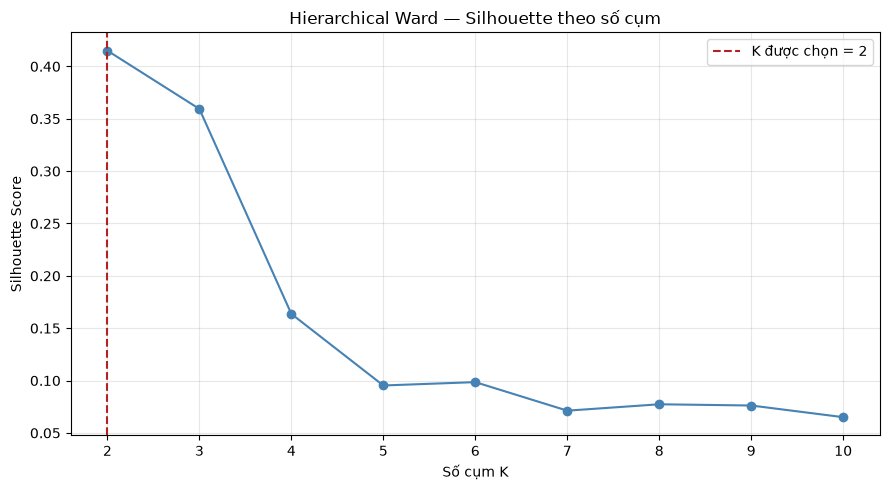

In [21]:
fig_silhouette, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    hierarchical_results["K"],
    hierarchical_results["Silhouette"],
    marker="o",
    color="steelblue"
)

ax.axvline(
    selected_k_hierarchical,
    color="firebrick",
    linestyle="--",
    label=f"K được chọn = {selected_k_hierarchical}"
)

ax.set_title("Hierarchical Ward — Silhouette theo số cụm")
ax.set_xlabel("Số cụm K")
ax.set_ylabel("Silhouette Score")
ax.set_xticks(k_values)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [22]:
display(hierarchical_results.round(6))

,K,Silhouette,Davies_Bouldin,Calinski_Harabasz,Min_cluster_size,Max_cluster_size
0,2,0.415037,1.011878,2562.366845,1361,1639
1,3,0.359396,1.624952,1614.609482,277,1639
2,4,0.163656,2.238757,1181.438392,277,1084
3,5,0.095319,2.618447,957.673150,277,971
4,6,0.098511,2.445107,815.023448,18,971
5,7,0.071267,2.355499,715.196129,18,668
6,8,0.077361,2.270394,639.197799,18,631
7,9,0.076194,2.269641,575.682892,18,631
8,10,0.065053,2.393432,525.408895,18,631


Thực nghiệm Hierarchical Clustering với phương pháp Ward được tiến hành trên tập dữ liệu cố định gồm 3.000 mẫu và 104 thành phần PCA, với số cụm K từ 2 đến 10. Kết quả cho thấy K=2 đạt Silhouette cao nhất (0,415037), Davies–Bouldin thấp nhất (1,011878) và Calinski–Harabasz cao nhất (2562,366845). Như vậy, cả ba chỉ số đánh giá nội bộ đều ủng hộ lựa chọn K=2 trong phạm vi khảo sát, phù hợp với cấu trúc hai nhánh lớn quan sát trên Dendrogram.

Hai cụm có quy mô lần lượt là 1.361 và 1.639 mẫu. Khi tăng số cụm, chất lượng đánh giá nội bộ nhìn chung giảm; tại K=6 xuất hiện một cụm nhỏ gồm 18 mẫu. Vì vậy, K=2 được chọn làm cấu hình chính. Ý nghĩa hoạt động của các cụm và mức độ tương đồng với nhãn thực tế sẽ được phân tích ở bước đánh giá bên ngoài.

## 4: Đánh giá ngoài bằng ARI và NMI

Đối chiếu nhãn cụm Hierarchical với nhãn hoạt động thực tế
trên cùng 3.000 mẫu và đúng thứ tự dòng.

- K được chọn ở bước 3 là cấu hình chính.
- K=6 được đánh giá bổ sung để đối chiếu với thực nghiệm của K-Means.
- ARI và NMI chỉ dùng đánh giá sau phân cụm, không dùng chọn lại K.

In [23]:
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
)

# Các biến này phải được tạo từ những bước trước.
assert "y_reference" in globals(), "Hãy chạy lại bước 1."
assert "labels_hierarchical_by_k" in globals(), "Hãy chạy lại bước 3."
assert "selected_k_hierarchical" in globals(), "Hãy chạy lại bước 3.3."

assert y_reference.shape == (3000,), "Sai kích thước nhãn tham chiếu."

# Kiểm tra nhãn tham chiếu vẫn đúng thứ tự trong bảng dữ liệu.
assert np.array_equal(
    y_reference,
    data["Activity"].to_numpy()
), "Nhãn tham chiếu không khớp thứ tự dữ liệu."

print("Số mẫu đánh giá:", len(y_reference))
print("Số hoạt động thực tế:", len(np.unique(y_reference)))
print("K chính đã chọn:", selected_k_hierarchical)

Số mẫu đánh giá: 3000
Số hoạt động thực tế: 6
K chính đã chọn: 2


Tính ARI và NMI

In [24]:
# Đánh giá mô hình chính và trường hợp bổ sung K=6.
k_to_evaluate = sorted({selected_k_hierarchical, 6})
external_rows = []

for k in k_to_evaluate:
    predicted_labels = labels_hierarchical_by_k[k]

    assert predicted_labels.shape == y_reference.shape
    assert len(np.unique(predicted_labels)) == k

    ari = adjusted_rand_score(
        y_reference,
        predicted_labels
    )

    nmi = normalized_mutual_info_score(
        y_reference,
        predicted_labels,
        average_method="arithmetic"
    )

    external_rows.append({
        "K": k,
        "Role": (
            "Mô hình chính"
            if k == selected_k_hierarchical
            else "Thực nghiệm bổ sung"
        ),
        "ARI": ari,
        "NMI": nmi,
    })

external_results_hierarchical = pd.DataFrame(external_rows)

print("KẾT QUẢ ĐÁNH GIÁ NGOÀI:")
display(external_results_hierarchical.round(6))

print("K chính được giữ nguyên:", selected_k_hierarchical)

KẾT QUẢ ĐÁNH GIÁ NGOÀI:


,K,Role,ARI,NMI
0,2,Mô hình chính,0.332287,0.556796
1,6,Thực nghiệm bổ sung,0.326823,0.482121


K chính được giữ nguyên: 2


## 5: Trực quan hóa và đối chiếu kết quả phân cụm

Hiển thị kết quả của mô hình chính trên hai thành phần PC1–PC2,
đặt cạnh biểu đồ nhãn hoạt động thực tế để quan sát.

Mô hình đã phân cụm trên đủ 104 thành phần PCA.
PC1–PC2 chỉ được dùng để vẽ, không chạy lại PCA hoặc mô hình.

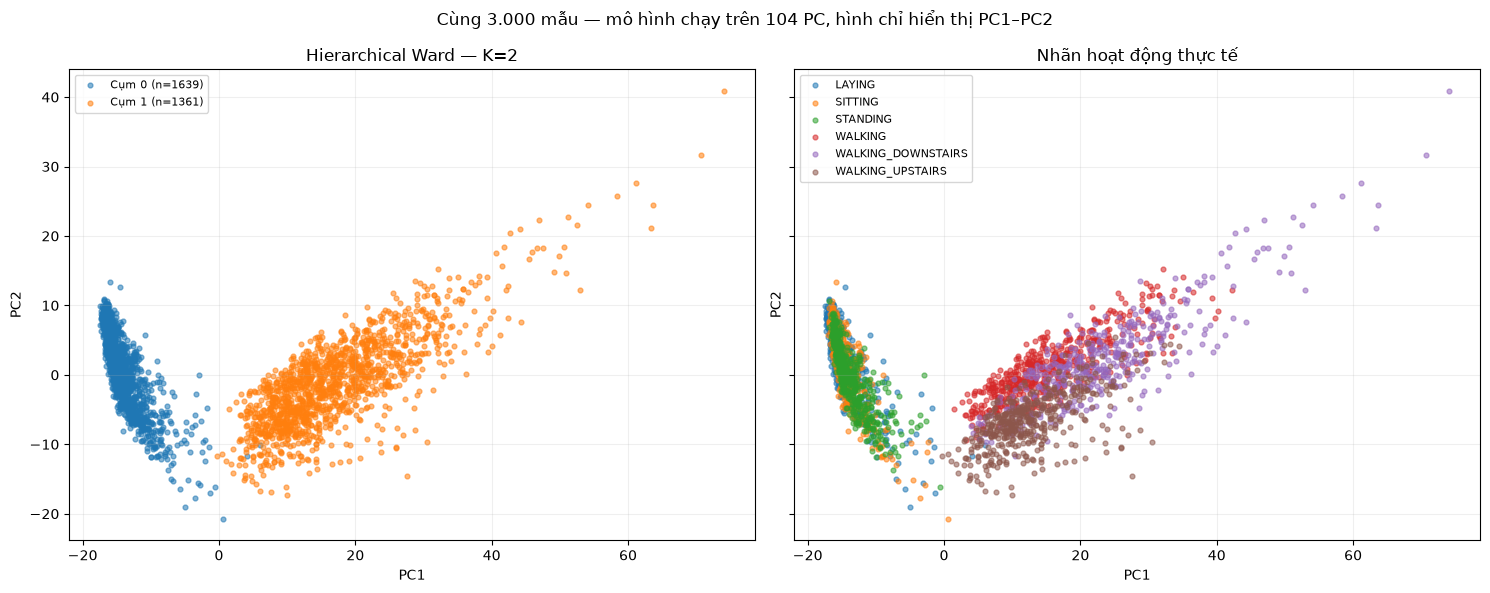

In [25]:
assert len(labels_hierarchical) == len(data)
assert np.array_equal(
    labels_hierarchical,
    labels_hierarchical_by_k[selected_k_hierarchical]
)

# Giữ nguyên thứ tự mẫu.
plot_data = data[["PC1", "PC2", "ActivityName"]].copy()
plot_data["Cluster"] = labels_hierarchical

fig_clusters_pca2d, axes = plt.subplots(
    1, 2,
    figsize=(15, 6),
    sharex=True,
    sharey=True
)

palette = plt.get_cmap("tab10")

# Bên trái: nhãn cụm do Ward tạo ra.
for i, cluster in enumerate(sorted(plot_data["Cluster"].unique())):
    subset = plot_data[plot_data["Cluster"] == cluster]

    axes[0].scatter(
        subset["PC1"],
        subset["PC2"],
        s=12,
        alpha=0.55,
        color=palette(i),
        label=f"Cụm {cluster} (n={len(subset)})"
    )

# Bên phải: nhãn hoạt động thực tế.
for i, activity in enumerate(sorted(plot_data["ActivityName"].unique())):
    subset = plot_data[plot_data["ActivityName"] == activity]

    axes[1].scatter(
        subset["PC1"],
        subset["PC2"],
        s=12,
        alpha=0.55,
        color=palette(i),
        label=activity
    )

axes[0].set_title(f"Hierarchical Ward — K={selected_k_hierarchical}")
axes[1].set_title("Nhãn hoạt động thực tế")

for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

fig_clusters_pca2d.suptitle(
    "Cùng 3.000 mẫu — mô hình chạy trên 104 PC, hình chỉ hiển thị PC1–PC2"
)

fig_clusters_pca2d.tight_layout()
plt.show()

### 5.1. Đối chiếu cụm với hoạt động thực tế

Bảng số lượng cho biết mỗi cụm chứa bao nhiêu mẫu của từng hoạt động.
Bảng tỷ lệ theo hàng cho biết thành phần hoạt động bên trong mỗi cụm.
Nhãn hoạt động chỉ được sử dụng sau khi đã phân cụm và chọn K.

In [26]:
activity_order = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING",
]

activity_crosstab_hierarchical = pd.crosstab(
    plot_data["Cluster"],
    plot_data["ActivityName"]
).reindex(columns=activity_order, fill_value=0)

assert activity_crosstab_hierarchical.to_numpy().sum() == len(X)

# Chia cho tổng số mẫu của từng cụm.
activity_percent_hierarchical = (
    activity_crosstab_hierarchical
    .div(activity_crosstab_hierarchical.sum(axis=1), axis=0)
    .mul(100)
)

print("SỐ MẪU CỦA TỪNG HOẠT ĐỘNG TRONG MỖI CỤM:")
display(activity_crosstab_hierarchical)

print("TỶ LỆ HOẠT ĐỘNG BÊN TRONG MỖI CỤM (%):")
display(activity_percent_hierarchical.round(2))

SỐ MẪU CỦA TỪNG HOẠT ĐỘNG TRONG MỖI CỤM:


ActivityName,WALKING,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,SITTING,STANDING,LAYING
Cluster,,,,,,
0,0,0,0,518,555,566
1,502,450,409,0,0,0


TỶ LỆ HOẠT ĐỘNG BÊN TRONG MỖI CỤM (%):


ActivityName,WALKING,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,SITTING,STANDING,LAYING
Cluster,,,,,,
0,0.00,0.00,0.00,31.6,33.86,34.53
1,36.88,33.06,30.05,0.0,0.00,0.00


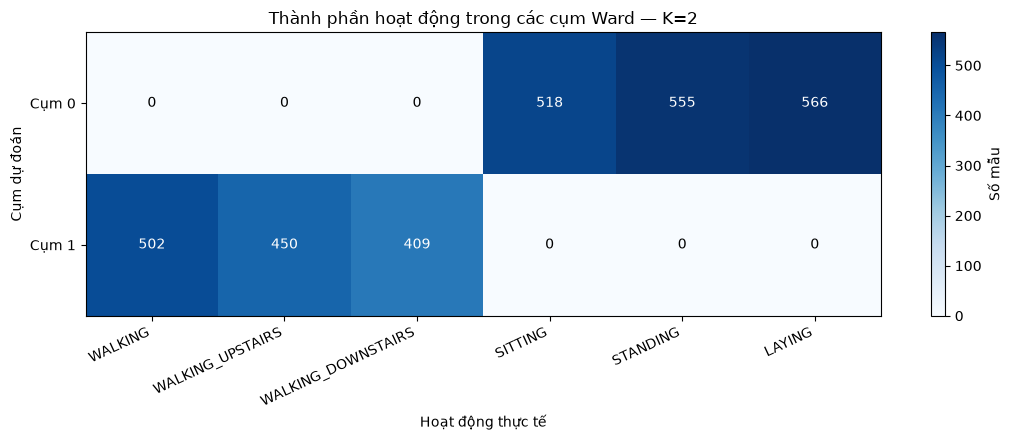

In [27]:
table = activity_crosstab_hierarchical
values = table.to_numpy()

fig_activity_heatmap, ax = plt.subplots(figsize=(11, 4.5))

heatmap = ax.imshow(
    values,
    cmap="Blues",
    aspect="auto"
)

ax.set_xticks(range(len(table.columns)))
ax.set_xticklabels(table.columns, rotation=25, ha="right")

ax.set_yticks(range(len(table.index)))
ax.set_yticklabels([f"Cụm {c}" for c in table.index])

# Ghi số mẫu vào từng ô.
for row in range(values.shape[0]):
    for col in range(values.shape[1]):
        value = int(values[row, col])

        ax.text(
            col, row, str(value),
            ha="center",
            va="center",
            color="white" if value > values.max() * 0.55 else "black"
        )

ax.set_title(
    f"Thành phần hoạt động trong các cụm Ward — K={selected_k_hierarchical}"
)
ax.set_xlabel("Hoạt động thực tế")
ax.set_ylabel("Cụm dự đoán")

fig_activity_heatmap.colorbar(
    heatmap,
    ax=ax,
    label="Số mẫu"
)

fig_activity_heatmap.tight_layout()
plt.show()